# Calibration of science frames

`author` Julien Morin <julien.morin@umontpellier.fr>

`date` 11 Oct 2023

Reference: *Handbook of CCD Astronomy*, §4.5 and __[CCD Data Reduction Guide #Reducing science images](https://www.astropy.org/ccd-reduction-and-photometry-guide/v/dev/notebooks/06-00-Reducing-science-images.html)__
* apply bias and flat field correction to science frames
* check statistical properties
* save as FITS file in the `processed` folder

In [1]:
# import and settings
%matplotlib notebook
import os
import numpy as np
import matplotlib.pyplot as plt
import astropy.io.fits as pf
from astropy.stats import mad_std
from astropy import units as u
from astropy.visualization import ZScaleInterval
import ccdproc as ccdp

## Load previously computed data 

In [2]:
# define CCD characteristics
ccd_gain = 0.966 * u.electron / u.adu
ccd_ron = 6.485 * u.electron

In [3]:
# load master bias, master flat, print info
master_bias = ccdp.CCDData.read('reference/master_bias.fits', unit='adu')
master_bias.to_hdu().info()
print('\n')
master_flatH = ccdp.CCDData.read('reference/master_flatH.fits', unit=None)
master_flatH.to_hdu().info()

INFO: using the unit adu passed to the FITS reader instead of the unit adu in the FITS file. [astropy.nddata.ccddata]
Filename: (No file associated with this HDUList)
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      35   (2048, 2048)   float64   


Filename: (No file associated with this HDUList)
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (2048, 2048)   float64   
  1  MASK          1 ImageHDU         8   (2048, 2048)   uint8   
  2  UNCERT        1 ImageHDU         9   (2048, 2048)   float64   


In [4]:
### ToDo: check statistics of the master frames

## Load and examine science frames

In [5]:
# create raw image collection
ifc_raw = ccdp.ImageFileCollection('raw/')
# create science image collection and print summary and statistics
ifc_sci = ifc_raw.filter(imagetyp='Light Frame', filter='Halpha_OHP')
sci_summary = ifc_sci.summary
print(sci_summary['file', 'date-obs', 'imagetyp', 'object', 'filter', 'exposure'])

         file                date-obs          imagetyp   object   filter   exposure
--------------------- ---------------------- ----------- ------- ---------- --------
raw/Wasp_33-0001.fits 2020-09-15T23:08:38.73 Light Frame Wasp_33 Halpha_OHP     10.0
raw/Wasp_33-0003.fits 2020-09-15T23:09:10.70 Light Frame Wasp_33 Halpha_OHP     10.0
raw/Wasp_33-0009.fits 2020-09-15T23:10:46.19 Light Frame Wasp_33 Halpha_OHP     10.0


In [6]:
# create ccd object for one science frame and print statistics, plot image + histogram
path_sci = "raw/Wasp_33-0009.fits"
ccd_sci = ccdp.CCDData.read(path_sci, unit='adu')

### ToDo: 
###       print statistics
###       display image
###       display histogram

## Correct science images by master bias

In [7]:
# bias subtract the science image and compare statistics
ccd_sci_b = ccdp.subtract_bias(ccd_sci, master_bias)
### ToDo: print statistics for both images

In [8]:
# at this stage the science frame does not have uncertainty set
print((ccd_sci_b.uncertainty))
print("\n")
# create it now
ccd_sci_b = ccdp.create_deviation(ccd_sci_b, gain=ccd_gain, readnoise=ccd_ron, disregard_nan=True)
# print statistics for the uncertainty array
npix = ccd_sci_b.uncertainty.array.shape[0]*ccd_sci_b.uncertainty.array.shape[1]
print('npix    mean    median  std  ')
print('-----------------------------')
print("%7d %5.4f   %5.4f  %5.4f\n" % (npix, np.mean(ccd_sci_b.uncertainty.array.data), np.median(ccd_sci_b.uncertainty.array), np.std(ccd_sci_b.uncertainty.array)))

None


npix    mean    median  std  
-----------------------------
4194304 6.9549   6.7670  0.4649



## Correct sicence images by flat field

In [9]:
ccd_sci_bf = ccdp.flat_correct(ccd_sci_b, master_flatH)

In [10]:
### ToDo: check that the uncertainty array has been propagated, print its statistics

<IPython.core.display.Javascript object>


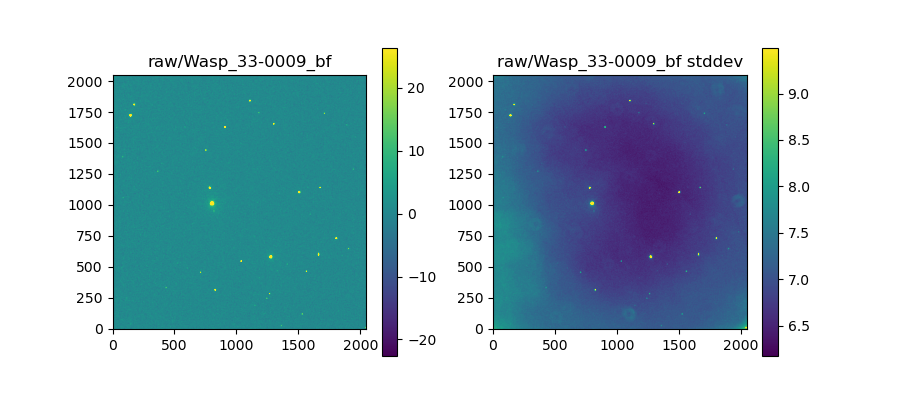

In [11]:
# display corrected science frame and uncertainty
fig = plt.figure(figsize=(9,4))
#
ax1 = fig.add_subplot(121)
interval1 = ZScaleInterval()
z1, z2 = interval1.get_limits(ccd_sci_bf)
im1 = ax1.imshow(ccd_sci_bf.data, origin='lower', vmin=z1, vmax=z2)
fig.colorbar(im1)
ax1.set_title(os.path.splitext(path_sci)[0] + '_bf')
#
ax2 = fig.add_subplot(122)
interval1 = ZScaleInterval()
z1, z2 = interval1.get_limits(ccd_sci_bf.uncertainty.array)
im2 = ax2.imshow(ccd_sci_bf.uncertainty.array, origin='lower', vmin=z1, vmax=z2)
fig.colorbar(im2)
ax2.set_title(os.path.splitext(path_sci)[0] + '_bf stddev')
plt.show()

## Apply gain correction and save processed file

In [12]:
ccd_sci_bf = ccdp.gain_correct(ccd_sci_bf, ccd_gain)

In [13]:
### ToDo: check statistics and unit of the gain-corrected image

In [14]:
### Further work:
###  - compute master dark, dark current, identify hot pixels (HP)
###  - identify cosmic rays (CR)
###  - try a HP/CR correction method (median filtering or masking)
### see ccdproc tutorials:
###  https://www.astropy.org/ccd-reduction-and-photometry-guide/v/dev/notebooks/06-03-science-images-calibration-examples.html
###  https://www.astropy.org/ccd-reduction-and-photometry-guide/v/dev/notebooks/08-01-Identifying-hot-pixels.html
###  https://www.astropy.org/ccd-reduction-and-photometry-guide/v/dev/notebooks/08-03-Cosmic-ray-removal.html

In [15]:
# save calibrated science-frame
bname_sci = os.path.split(path_sci)[1] # get file base name
path_sci_cal = 'processed/' + os.path.splitext(bname_sci)[0] + '_bf' + os.path.splitext(bname_sci)[1] # set full path and add suffix to basename
#ccd_sci_bf.write(path_sci_cal)
ccd_sci_bf.write(path_sci_cal, overwrite=True) # if the file already exists